# HR Analytics - Employee Attrition
## Notebook 1: Data Cleaning & Exploratory Data Analysis

**Goal:** understand *who* leaves the organisation and *why*, before building any model.

**Workflow**
1. Load & inspect the raw data
2. Data-quality audit (missing values, duplicates, inconsistent text)
3. Cleaning & feature engineering
4. Exploratory Data Analysis - age, gender, department, job role, salary, satisfaction, overtime, experience
5. Key insights

> **Data note:** the dataset is a *synthetic* 1,470-employee HR dataset modelled on the IBM HR Analytics structure
> (see `src/generate_dataset.py`). Replace `data/raw/HR_Employee_Attrition.csv` with a real export to re-run on live data.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data_cleaning as dc
import eda

eda.set_style()
IMG = "../images/eda"
pd.set_option("display.max_columns", 50)

## 1. Load & inspect the raw data

In [2]:
raw = pd.read_csv("../data/raw/HR_Employee_Attrition.csv")
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Shape: 1,490 rows x 32 columns


,EmployeeID,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,NumCompaniesWorked,JobLevel,...,StockOptionLevel,BusinessTravel,DistanceFromHome,OverTime,JobSatisfaction,EnvironmentSatisfaction,RelationshipSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,TrainingTimesLastYear,EmployeeCount,Over18,StandardHours,Attrition
0,1942,45,Female,Divorced,3,Technical Degree,Research & Development,Manufacturing Director,27.0,4,2,2,1,1,5,...,1,Travel_Frequently,15,No,3.0,4,3,3,2,3,0,1,Y,80,No
1,1298,34,Male,Single,3,Medical,Research & Development,Research Scientist,15.0,3,1,0,2,0,3,...,1,Travel_Rarely,3,Yes,2.0,3,4,4,4,3,2,1,Y,80,No
2,1272,40,Female,Single,3,Life Sciences,Human Resources,HR Manager,19.0,3,3,3,3,3,5,...,1,Travel_Rarely,6,No,1.0,3,3,3,3,3,5,1,Y,80,No
3,1775,37,Male,Single,3,Medical,Research & Development,Manufacturing Director,18.0,13,11,1,5,0,5,...,1,Travel_Rarely,17,Yes,3.0,2,2,4,3,3,0,1,Y,80,No
4,1421,38,Female,Married,3,Technical Degree,Sales,Sales Manager,18.0,5,2,2,4,4,5,...,1,Travel_Frequently,2,No,1.0,2,2,2,3,4,3,1,Y,80,No


In [3]:
raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
EmployeeID,1490.0,1734.2,424.8,1001.0,1365.2,1733.5,2101.8,2470.0
Age,1490.0,36.9,8.8,18.0,31.0,37.0,43.0,60.0
Education,1490.0,2.9,1.0,1.0,2.0,3.0,4.0,5.0
TotalWorkingYears,1476.0,14.8,8.9,0.0,8.0,15.0,21.0,41.0
YearsAtCompany,1490.0,7.2,5.4,0.0,3.0,6.0,10.0,32.0
YearsInCurrentRole,1490.0,4.7,4.0,0.0,2.0,4.0,7.0,26.0
YearsSinceLastPromotion,1490.0,1.5,1.7,0.0,0.0,1.0,2.0,19.0
YearsWithCurrManager,1490.0,4.6,3.8,0.0,2.0,4.0,6.0,28.0
NumCompaniesWorked,1490.0,2.0,1.4,0.0,1.0,2.0,3.0,8.0
JobLevel,1490.0,3.1,1.2,1.0,2.0,3.0,4.0,5.0


## 2. Data-quality audit

In [4]:
audit = dc.audit(raw)
audit[audit["missing"] > 0]

,dtype,missing,missing_%,unique
TotalWorkingYears,float64,14,0.94,42
MonthlyIncome,float64,27,1.81,1351
BusinessTravel,str,11,0.74,3
JobSatisfaction,float64,17,1.14,4


In [5]:
print("Exact duplicate rows      :", raw.duplicated().sum())
print("Duplicate EmployeeIDs     :", raw["EmployeeID"].duplicated().sum())
print("Constant columns          :", [c for c in raw.columns if raw[c].nunique() <= 1])
print()
print("Department spellings found:", raw["Department"].unique().tolist())
print("Job roles (sample)        :", sorted(raw["JobRole"].dropna().unique())[:6])

Exact duplicate rows      : 20
Duplicate EmployeeIDs     : 20
Constant columns          : ['EmployeeCount', 'Over18', 'StandardHours']

Department spellings found: ['Research & Development', 'Human Resources', 'Sales', ' HUMAN RESOURCES ', ' SALES ', ' RESEARCH & DEVELOPMENT ']
Job roles (sample)        : ['HR Executive', 'HR Manager', 'Healthcare Representative', 'Laboratory Technician', 'Manufacturing Director', 'Research Director']


**Findings**
- 68 missing cells across `MonthlyIncome`, `JobSatisfaction`, `TotalWorkingYears`, `BusinessTravel`
- 20 duplicated employee records
- Inconsistent text (`" SALES "`, lower-case job roles)
- 3 constant columns (`EmployeeCount`, `Over18`, `StandardHours`) carry no information

## 3. Cleaning - step by step

In [6]:
df = dc.remove_duplicates(raw)
print(f"Duplicates removed: {len(raw) - len(df)}  ->  {len(df):,} unique employees")

Duplicates removed: 20  ->  1,470 unique employees


In [7]:
df = dc.standardize_text(df)
print("Department values now:", df["Department"].unique().tolist())

Department values now: ['Research & Development', 'Human Resources', 'Sales']


In [8]:
df, dropped = dc.drop_constant_columns(df)
print("Dropped constant columns:", dropped)

Dropped constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


**Missing values strategy**
- `MonthlyIncome` -> median of the employee's *job level* (pay is driven by level)
- `TotalWorkingYears` -> median of the employee's *age band*
- Other numeric -> median, categorical -> mode

In [9]:
print("Missing before:", int(df.isna().sum().sum()))
df = dc.impute_missing(df)
df = dc.fix_dtypes_and_logic(df)
print("Missing after :", int(df.isna().sum().sum()))

Missing before: 68
Missing after : 0


### Feature engineering
Bands and readable labels are created here so they can be reused directly in Power BI.

In [10]:
df = dc.engineer_features(df)
df[["Age", "AgeGroup", "MonthlyIncome", "SalaryBand", "TotalWorkingYears", "ExperienceBand",
    "JobSatisfaction", "JobSatisfactionLevel", "Attrition_Flag"]].head()

,Age,AgeGroup,MonthlyIncome,SalaryBand,TotalWorkingYears,ExperienceBand,JobSatisfaction,JobSatisfactionLevel,Attrition_Flag
0,45,36-45,14484,12K+,27,20+ yrs,3,High,0
1,34,26-35,9743,9K-12K,15,11-20 yrs,2,Medium,0
2,40,36-45,14173,12K+,19,11-20 yrs,1,Low,0
3,37,36-45,14439,12K+,18,11-20 yrs,3,High,0
4,38,36-45,13511,12K+,18,11-20 yrs,1,Low,0


In [11]:
df.to_csv("../data/processed/cleaned_hr_data.csv", index=False)
print("Saved cleaned dataset:", df.shape)

Saved cleaned dataset: (1470, 42)


## 4. Exploratory Data Analysis

### 4.1 Overall attrition

Total employees : 1,470
Employees left  : 227
Attrition rate  : 15.4%
Average age     : 36.9


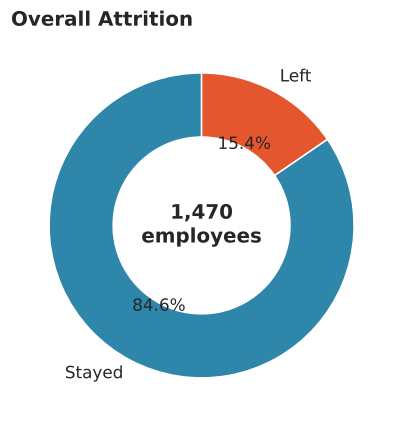

In [12]:
total, left = len(df), int(df["Attrition_Flag"].sum())
print(f"Total employees : {total:,}")
print(f"Employees left  : {left}")
print(f"Attrition rate  : {left/total:.1%}")
print(f"Average age     : {df['Age'].mean():.1f}")
eda.plot_overview(df, IMG);

### 4.2 Department & gender

,Employees,Left,Attrition_%
Department,,,
Human Resources,147,21,14.3
Research & Development,880,125,14.2
Sales,443,81,18.3


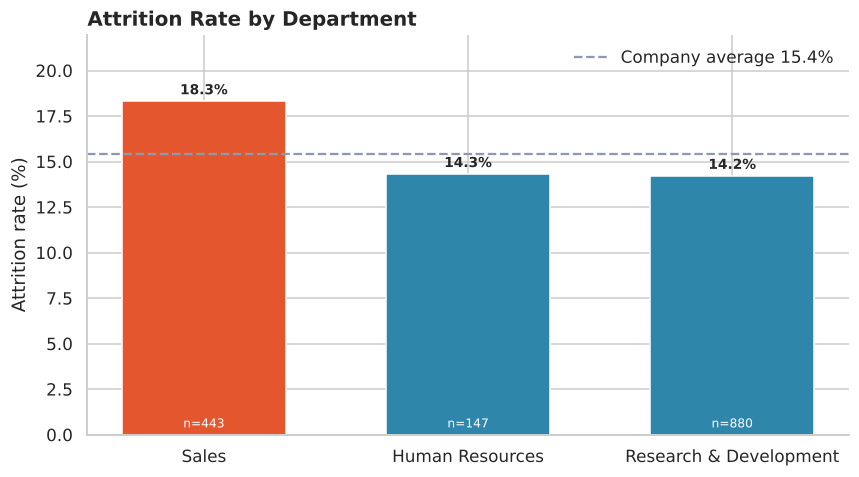

In [13]:
display_tbl = eda.attrition_rate_table(df, "Department")
eda.plot_department(df, IMG)
display_tbl

,Employees,Left,Attrition_%
Gender,,,
Female,577,100,17.3
Male,893,127,14.2


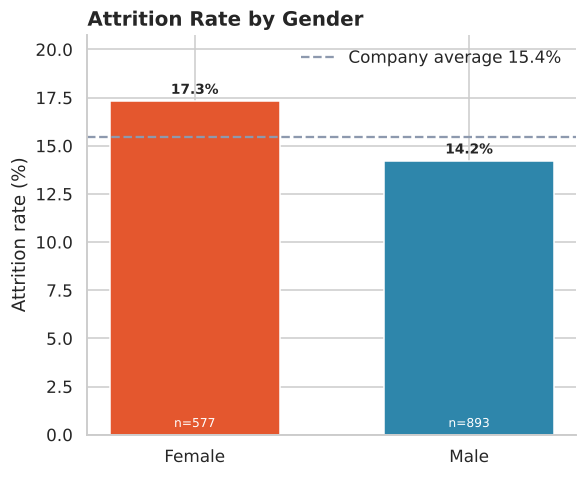

In [14]:
tbl = eda.attrition_rate_table(df, "Gender")
eda.plot_gender(df, IMG)
tbl

> Gender shows a small gap, but with ~600 female employees a 3-point difference is within normal sampling noise;
> it should be monitored, not treated as a driver.

### 4.3 Job role

,Employees,Left,Attrition_%
JobRole,,,
Sales Representative,96,27,28.1
Laboratory Technician,226,49,21.7
HR Executive,98,18,18.4
Sales Executive,315,53,16.8
Healthcare Representative,117,19,16.2
Research Scientist,280,43,15.4
HR Manager,49,3,6.1
Manufacturing Director,164,10,6.1
Research Director,93,4,4.3


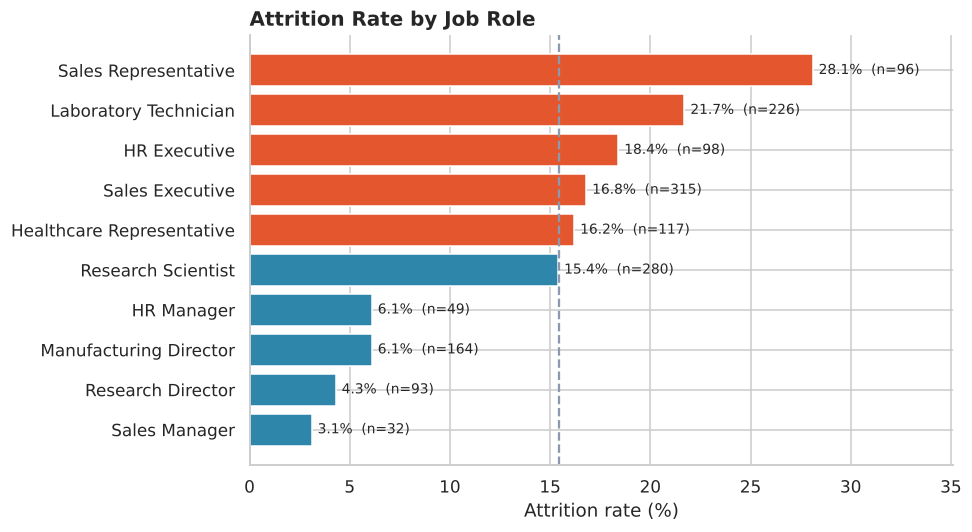

In [15]:
tbl = eda.attrition_rate_table(df, "JobRole").sort_values("Attrition_%", ascending=False)
eda.plot_job_role(df, IMG)
tbl

### 4.4 Age

,Employees,Left,Attrition_%
AgeGroup,,,
18-25,157,54,34.4
26-35,478,85,17.8
36-45,600,78,13.0
46-55,209,9,4.3
56+,26,1,3.8


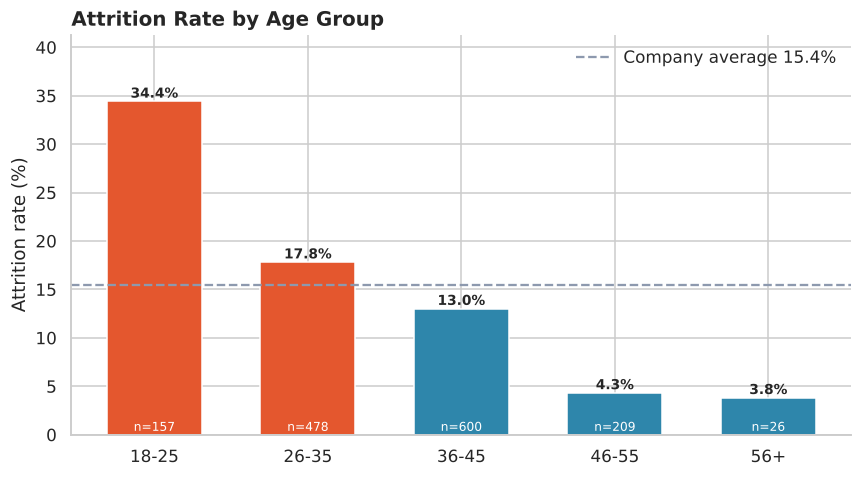

In [16]:
tbl = eda.attrition_rate_table(df, "AgeGroup", eda.ORDER["AgeGroup"])
eda.plot_age(df, IMG)
tbl

### 4.5 Salary

,Employees,Left,Attrition_%
SalaryBand,,,
< 3K,16,6,37.5
3K-6K,181,63,34.8
6K-9K,414,90,21.7
9K-12K,485,47,9.7
12K+,374,21,5.6


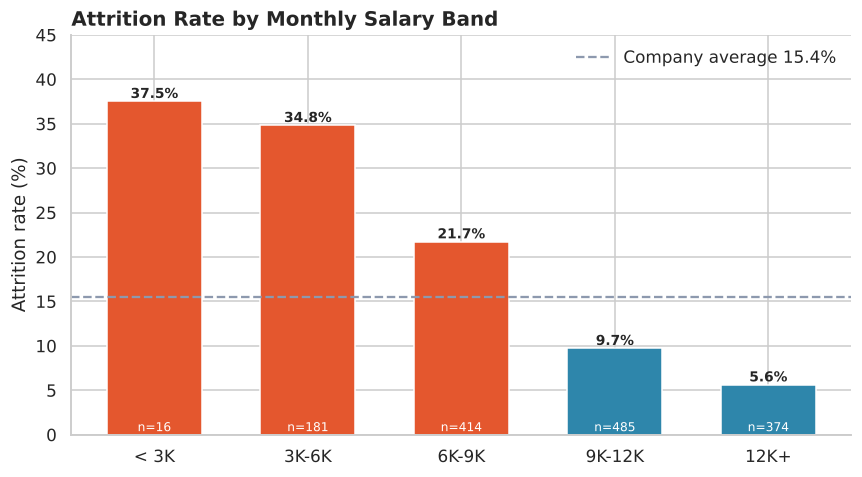

In [17]:
tbl = eda.attrition_rate_table(df, "SalaryBand", eda.ORDER["SalaryBand"])
eda.plot_salary(df, IMG)
tbl

### 4.6 Job satisfaction

,Employees,Left,Attrition_%
JobSatisfactionLevel,,,
Low,284,63,22.2
Medium,258,30,11.6
High,457,66,14.4
Very High,471,68,14.4


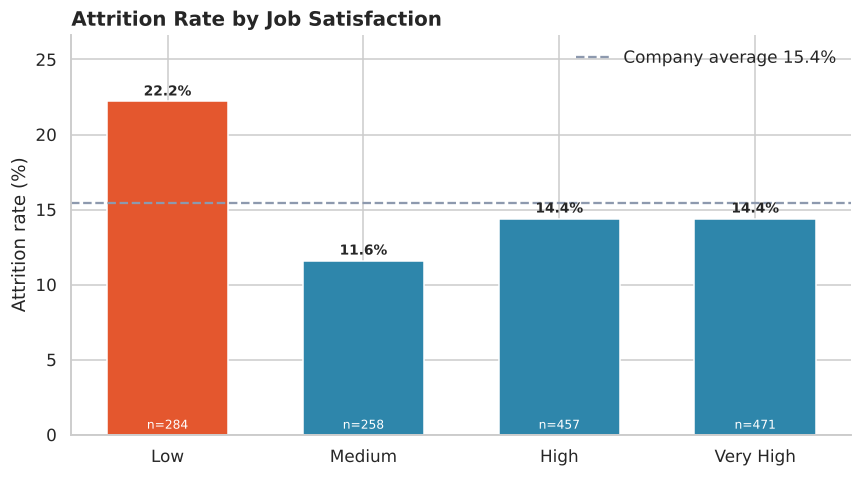

In [18]:
tbl = eda.attrition_rate_table(df, "JobSatisfactionLevel", eda.ORDER["JobSatisfactionLevel"])
eda.plot_job_satisfaction(df, IMG)
tbl

### 4.7 Overtime

,Employees,Left,Attrition_%
OverTime,,,
No,1054,119,11.3
Yes,416,108,26.0


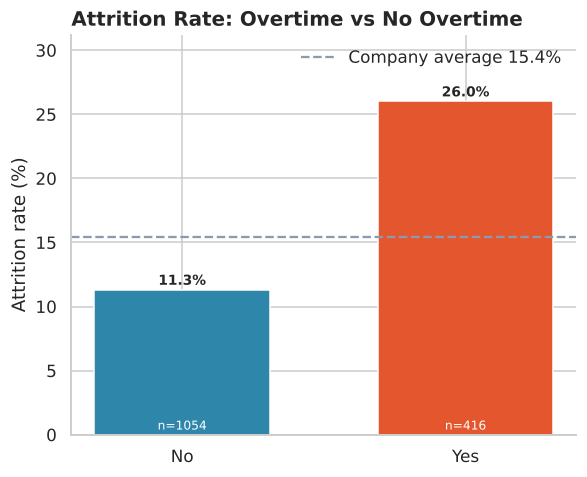

In [19]:
tbl = eda.attrition_rate_table(df, "OverTime", ["No", "Yes"])
eda.plot_overtime(df, IMG)
tbl

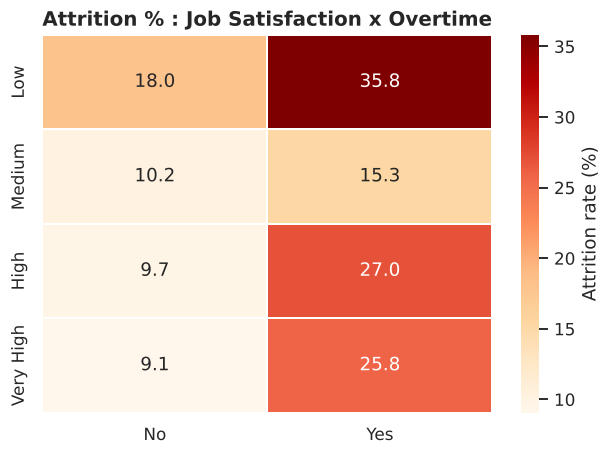

In [20]:
eda.plot_overtime_satisfaction_heatmap(df, IMG);

### 4.8 Experience & tenure

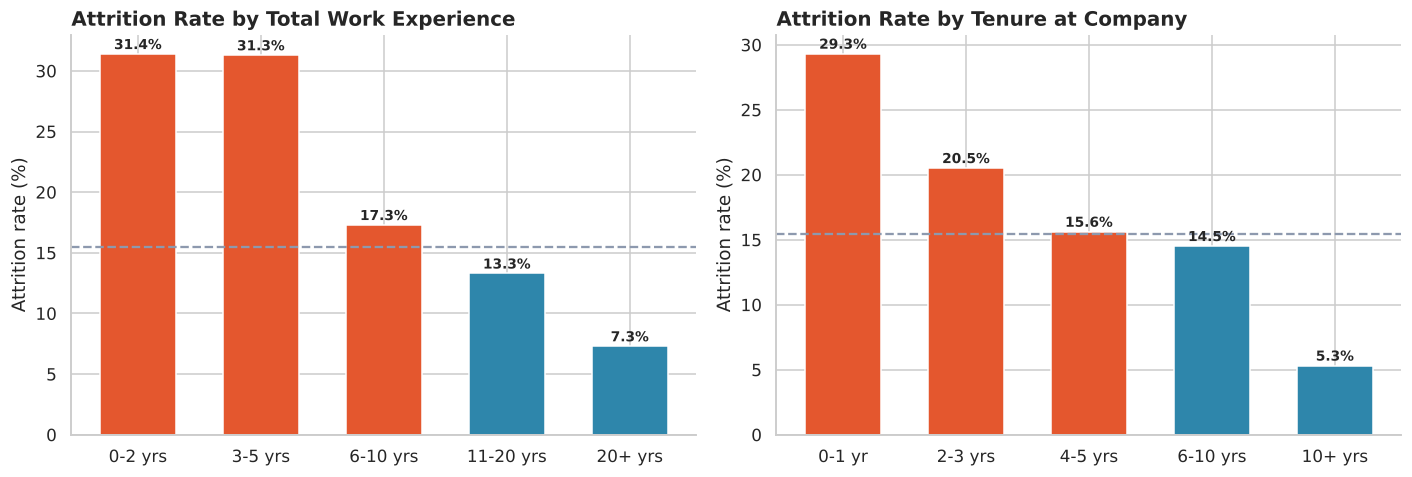

In [21]:
eda.plot_experience(df, IMG);

### 4.9 Education

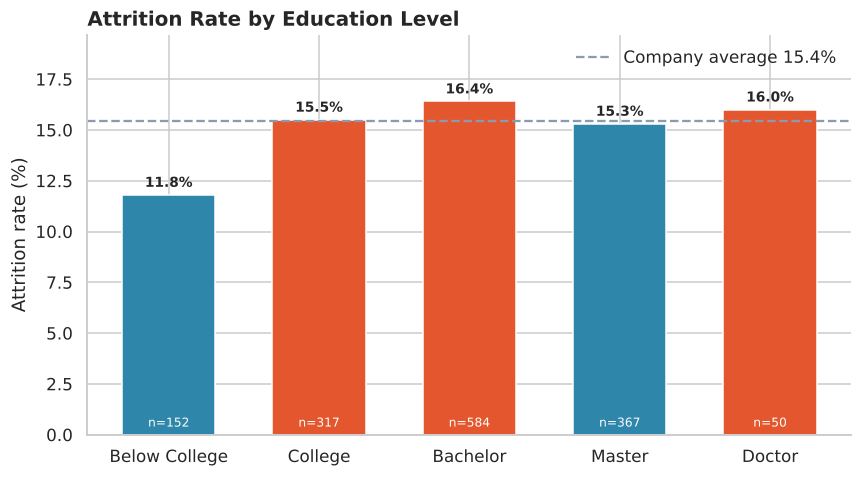

In [22]:
eda.plot_education(df, IMG);

### 4.10 Numeric profile of leavers vs stayers

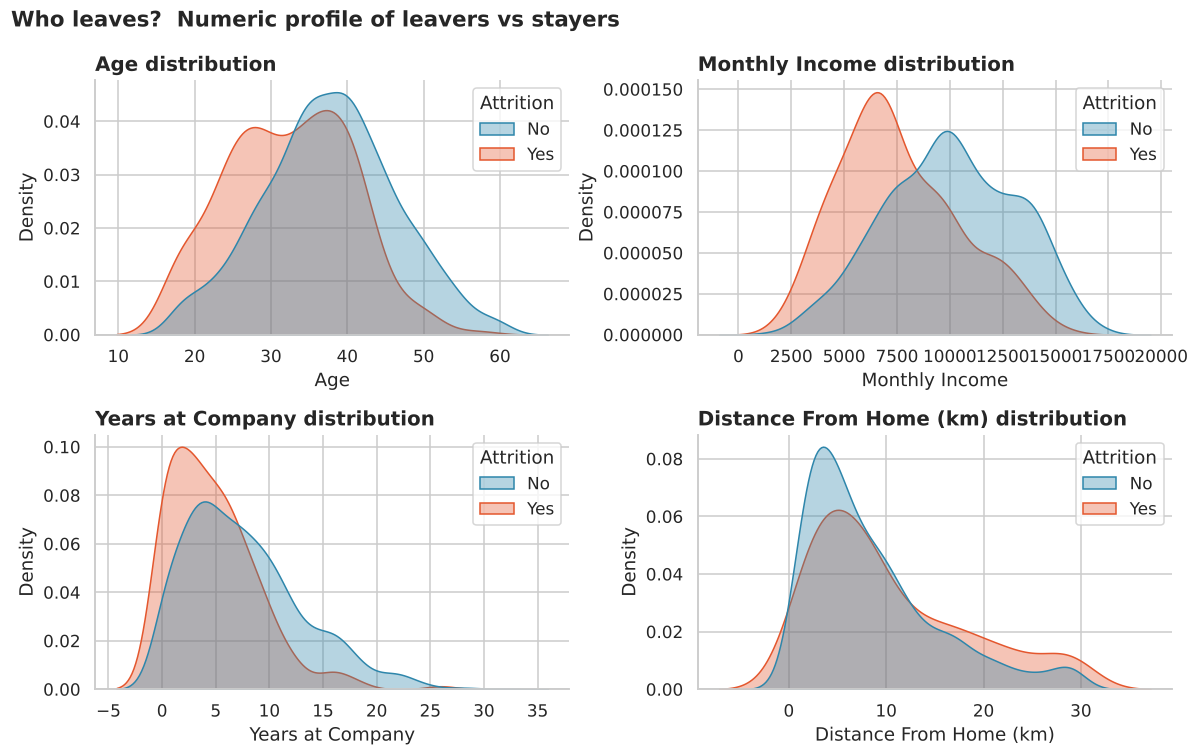

In [23]:
eda.plot_distributions(df, IMG);

In [24]:
df.groupby("Attrition")[["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "DistanceFromHome"]].mean().round(1)

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,DistanceFromHome
Attrition,,,,,
No,37.7,10033.7,15.6,7.6,8.5
Yes,32.4,7584.7,10.4,4.7,10.4


### 4.11 Correlation analysis

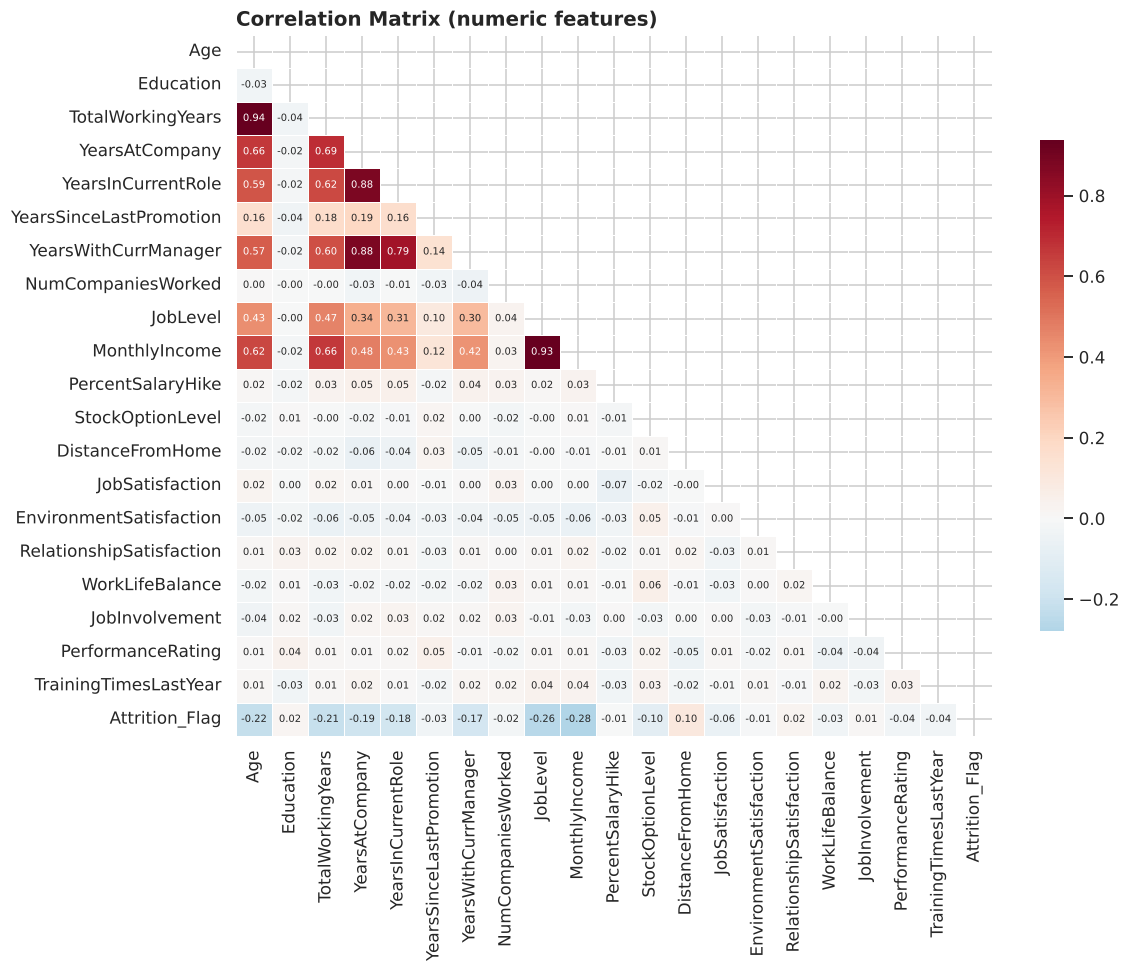

In [25]:
eda.plot_correlation(df, IMG);

In [26]:
eda.attrition_correlations(df)

MonthlyIncome           -0.278
JobLevel                -0.258
Age                     -0.220
TotalWorkingYears       -0.213
YearsAtCompany          -0.191
YearsInCurrentRole      -0.178
YearsWithCurrManager    -0.169
StockOptionLevel        -0.100
DistanceFromHome         0.098
JobSatisfaction         -0.057
TrainingTimesLastYear   -0.036
PerformanceRating       -0.035
Name: Attrition_Flag, dtype: float64

## 5. Key insights

| # | Insight | Evidence |
|---|---------|----------|
| 1 | **Overtime more than doubles attrition** | 26.0 % (overtime) vs 11.3 % (no overtime) |
| 2 | **Low pay is the strongest financial signal** | 35-38 % attrition below 6K/month vs 5.6 % above 12K |
| 3 | **Young employees leave the most** | 34 % for ages 18-25 vs 4 % for 46+ |
| 4 | **New joiners are the flight risk** | ~31 % attrition for employees with <= 5 years of experience |
| 5 | **Sales Representatives and Lab Technicians** are the hottest roles | 28 % and 22 % vs 15 % company average |
| 6 | **Low job satisfaction** lifts attrition | 22 % vs 12-14 % for other levels |
| 7 | **Senior / managerial roles are stable** | 3-6 % attrition |

**Next:** `02_Attrition_Prediction_Model.ipynb` turns these patterns into a predictive model.